# 01 — Prophet Sales Forecasting on Omnichannel Data

First model in my sales-forecasting comparison: Facebook Prophet, forecasting weekly revenue across the company's 8 European omnichannel markets. Prophet is the natural starting point here — it's interpretable, handles seasonality out of the box, and lets me fold in domain knowledge (promotions, COVID disruption) as explicit regressors rather than hoping a black-box model picks them up on its own.

Runs fine on CPU, no GPU needed.

**Walkthrough:**
1. Environment setup
2. Data loading & exploration
3. Preprocessing & train/test split
4. Prophet model configuration
5. Training (per-country models)
6. Forecasting & evaluation
7. Visualization
8. Exporting results


## Environment setup

Installing Prophet and the rest of the dependencies — CPU is plenty here.


In [1]:
# Cell 1: Install dependencies
!pip install -q prophet pandas numpy scikit-learn matplotlib seaborn

import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Prophet
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Reproducibility
SEED = 42
np.random.seed(SEED)

print(f'Setup complete.')
print(f'Prophet imported successfully.')

Setup complete.
Prophet imported successfully.


### Connecting to Google Drive

Reading data from and writing results to `/content/drive/MyDrive/ML_Prediction_Analysis/`.


In [ ]:
# Cell 1b: Mount Google Drive and configure paths
from google.colab import drive
drive.mount('/content/drive')

# --- Path Configuration ---
DRIVE_BASE = '/content/drive/MyDrive/ML_Prediction_Analysis'
DATA_DIR = f'{DRIVE_BASE}/Sample_Data'
RESULTS_DIR = f'{DRIVE_BASE}/Prophet_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)

# Data files
SALES_PATH = f'{DATA_DIR}/company_weekly_sales.csv'
ITEMS_PATH = f'{DATA_DIR}/company_items.csv'
LAUNCHES_PATH = f'{DATA_DIR}/company_country_launches.csv'

# Forecast configuration
FORECAST_HORIZON = 12  # Predict 12 weeks ahead

print(f'Data dir:     {DATA_DIR}')
print(f'Results dir:  {RESULTS_DIR}')
print(f'Forecast horizon: {FORECAST_HORIZON} weeks')
print(f'Drive mounted successfully.')

Mounted at /content/drive
Data dir:     /content/drive/MyDrive/ML_Prediction_Analysis/Sample_Data
Results dir:  /content/drive/MyDrive/ML_Prediction_Analysis/Prophet_Results
Forecast horizon: 12 weeks
Drive mounted successfully.


## Loading and exploring the data

Weekly aggregated sales across all 8 omnichannel markets.


In [3]:
# Cell 2: Load data
sales_df = pd.read_csv(SALES_PATH)
items_df = pd.read_csv(ITEMS_PATH)
launches_df = pd.read_csv(LAUNCHES_PATH)

sales_df['week_start_date'] = pd.to_datetime(sales_df['week_start_date'])

print(f'Sales dataset shape: {sales_df.shape}')
print(f'Date range: {sales_df.week_start_date.min()} to {sales_df.week_start_date.max()}')
print(f'Countries: {sorted(sales_df.country.unique())}')
print(f'\nColumn types:')
print(sales_df.dtypes)
sales_df.head()

Sales dataset shape: (3067, 12)
Date range: 2016-03-07 00:00:00 to 2025-12-22 00:00:00
Countries: ['BE', 'DE', 'ES', 'FR', 'IT', 'NL', 'PT', 'UK']

Column types:
week_start_date         datetime64[ns]
country                         object
total_revenue_eur              float64
order_count                      int64
total_quantity                   int64
avg_order_value_eur            float64
discount_amount_eur            float64
top_product_category            object
channel                         object
promotion_flag                   int64
holiday_event                   object
covid_period_flag                int64
dtype: object


,week_start_date,country,total_revenue_eur,order_count,total_quantity,avg_order_value_eur,discount_amount_eur,top_product_category,channel,promotion_flag,holiday_event,covid_period_flag
0,2016-03-07,IT,0.00,1,1,0.00,0.00,Compléments alimentaires,web,1,epifania,0
1,2016-03-14,IT,834.38,32,75,26.07,68.87,Antiparasitaire,mobile,1,NaN,0
2,2016-03-21,IT,1257.89,29,58,43.38,33.23,Compléments alimentaires,web,0,NaN,0
3,2016-03-28,IT,2190.96,62,120,35.34,103.39,Compléments alimentaires,web,0,NaN,0
4,2016-04-04,IT,2639.80,67,142,39.40,111.66,Ophtalmologie,web,0,NaN,0


In [4]:
# Cell 3: Data statistics per country
summary = sales_df.groupby('country').agg(
    weeks=('week_start_date', 'count'),
    start=('week_start_date', 'min'),
    end=('week_start_date', 'max'),
    avg_revenue=('total_revenue_eur', 'mean'),
    std_revenue=('total_revenue_eur', 'std'),
    promo_pct=('promotion_flag', 'mean')
).round(2)
summary['promo_pct'] = (summary['promo_pct'] * 100).round(1).astype(str) + '%'
print('=== Per-Country Summary ===')
print(summary.to_string())

=== Per-Country Summary ===
         weeks      start        end  avg_revenue  std_revenue promo_pct
country                                                                 
BE         304 2020-03-02 2025-12-22      6016.64      1701.67     15.0%
DE         434 2017-09-04 2025-12-22     15733.87      4439.12     13.0%
ES         395 2018-06-04 2025-12-22      9477.65      3243.43     16.0%
FR         467 2017-01-16 2025-12-22     12660.77      4030.16     15.0%
IT         512 2016-03-07 2025-12-22     10870.72      3245.19     15.0%
NL         334 2019-08-05 2025-12-22      7835.53      2183.87     15.0%
PT         258 2021-01-18 2025-12-22      4914.11      1713.25     16.0%
UK         363 2019-01-14 2025-12-22     14785.89      4334.54     14.0%


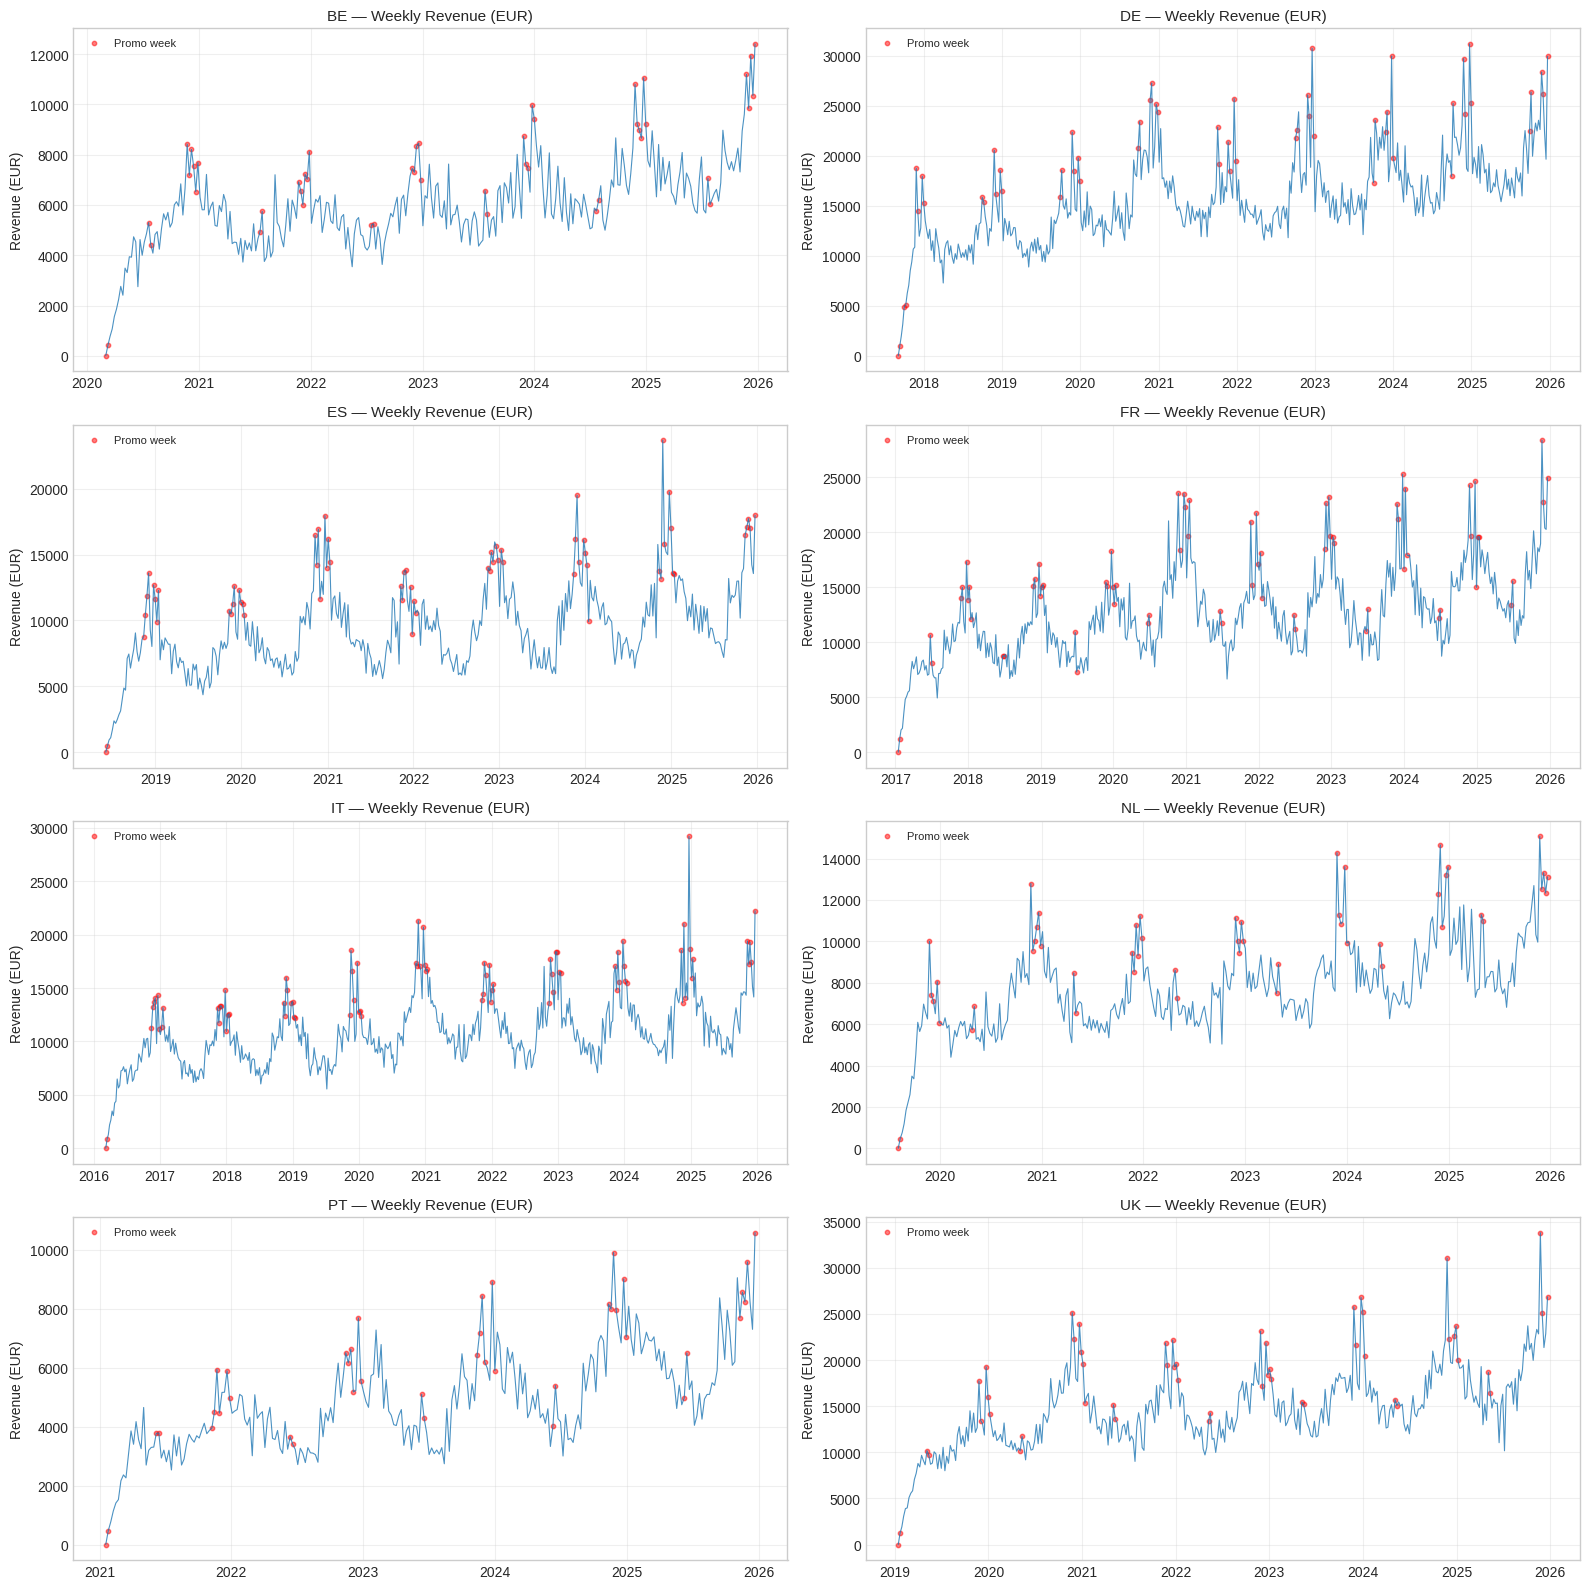

Data exploration plot saved.


In [5]:
# Cell 4: Visualize revenue time series per country
fig, axes = plt.subplots(4, 2, figsize=(16, 16), sharex=False)
countries = sorted(sales_df.country.unique())

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]
    country_data = sales_df[sales_df.country == country]
    ax.plot(country_data.week_start_date, country_data.total_revenue_eur,
            linewidth=0.8, alpha=0.8)
    # Highlight promotions
    promo_weeks = country_data[country_data.promotion_flag == 1]
    ax.scatter(promo_weeks.week_start_date, promo_weeks.total_revenue_eur,
              color='red', s=10, alpha=0.5, label='Promo week')
    ax.set_title(f'{country} — Weekly Revenue (EUR)', fontsize=11)
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/prophet_data_exploration.png', dpi=150, bbox_inches='tight')
plt.show()
print('Data exploration plot saved.')

## Preprocessing & train/test split

For each country I format the series into Prophet's expected `ds`/`y` columns, hold out the last 12 weeks as the test set, and attach two regressors: `promotion_flag` and `covid_period_flag`.


In [6]:
# Cell 5: Prepare Prophet-format data per country
def prepare_prophet_data(df, country, horizon=FORECAST_HORIZON):
    """Prepare train/test split for a single country."""
    country_df = df[df.country == country].copy()
    country_df = country_df.sort_values('week_start_date').reset_index(drop=True)

    # Prophet format
    prophet_df = pd.DataFrame({
        'ds': country_df['week_start_date'],
        'y': country_df['total_revenue_eur'],
        'promotion_flag': country_df['promotion_flag'].astype(float),
        'covid_period_flag': country_df['covid_period_flag'].astype(float),
    })

    # Train/test split: hold out last `horizon` weeks
    train = prophet_df.iloc[:-horizon].copy()
    test = prophet_df.iloc[-horizon:].copy()

    return train, test

# Quick check
train_de, test_de = prepare_prophet_data(sales_df, 'DE')
print(f'DE — Train: {len(train_de)} weeks, Test: {len(test_de)} weeks')
print(f'DE — Train period: {train_de.ds.min().date()} to {train_de.ds.max().date()}')
print(f'DE — Test period:  {test_de.ds.min().date()} to {test_de.ds.max().date()}')

DE — Train: 422 weeks, Test: 12 weeks
DE — Train period: 2017-09-04 to 2025-09-29
DE — Test period:  2025-10-06 to 2025-12-22


## Prophet model configuration

I'm sticking close to Prophet's defaults rather than over-tuning: automatic weekly/yearly seasonality detection, changepoint prior scale at 0.05 (the default flexibility for trend changes), and seasonality prior scale at 10. Both regressors (`promotion_flag`, `covid_period_flag`) get added explicitly.

Prophet handles the rest on its own — trend detection, yearly seasonality via Fourier terms, and since I'm supplying `promotion_flag` directly as a regressor, I don't need its built-in holiday-effects machinery on top of that.


In [7]:
# Cell 6: Prophet model builder
def build_prophet_model():
    """Create a configured Prophet model."""
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,   # Data is already weekly aggregated
        daily_seasonality=False,
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10,
        seasonality_mode='multiplicative',  # Better for growing series
        interval_width=0.95,
    )

    # Add external regressors
    model.add_regressor('promotion_flag', mode='multiplicative')
    model.add_regressor('covid_period_flag', mode='multiplicative')

    return model

print('Prophet model configuration:')
print('  - Yearly seasonality: True (multiplicative)')
print('  - Regressors: promotion_flag, covid_period_flag')
print('  - Changepoint prior: 0.05')
print('  - Interval width: 95%')

Prophet model configuration:
  - Yearly seasonality: True (multiplicative)
  - Regressors: promotion_flag, covid_period_flag
  - Changepoint prior: 0.05
  - Interval width: 95%


## Training — one model per country

I'm fitting a separate Prophet model per country rather than pooling everything, since each market has a different launch date, its own seasonality pattern, and a different growth trajectory. Trying to force them into one global model would wash out exactly the differences I care about.


In [8]:
# Cell 7: Train Prophet for all countries
countries = sorted(sales_df.country.unique())
prophet_models = {}
prophet_forecasts = {}
prophet_train_data = {}
prophet_test_data = {}
training_times = {}

print('Training Prophet models per country...')
print('=' * 50)

for country in countries:
    train, test = prepare_prophet_data(sales_df, country)
    prophet_train_data[country] = train
    prophet_test_data[country] = test

    # Build and fit
    start_time = time.time()
    model = build_prophet_model()
    model.fit(train)
    elapsed = time.time() - start_time
    training_times[country] = elapsed

    # Forecast on test period
    future = test[['ds', 'promotion_flag', 'covid_period_flag']].copy()
    forecast = model.predict(future)

    prophet_models[country] = model
    prophet_forecasts[country] = forecast

    print(f'  {country}: trained in {elapsed:.1f}s | '
          f'Train: {len(train)} wks | Test: {len(test)} wks')

total_training_time = sum(training_times.values())
print(f'\nTotal training time: {total_training_time:.1f}s ({total_training_time/60:.1f} min)')

Training Prophet models per country...
  BE: trained in 1.5s | Train: 292 wks | Test: 12 wks
  DE: trained in 0.1s | Train: 422 wks | Test: 12 wks
  ES: trained in 0.1s | Train: 383 wks | Test: 12 wks
  FR: trained in 0.1s | Train: 455 wks | Test: 12 wks
  IT: trained in 0.1s | Train: 500 wks | Test: 12 wks
  NL: trained in 0.1s | Train: 322 wks | Test: 12 wks
  PT: trained in 0.1s | Train: 246 wks | Test: 12 wks
  UK: trained in 0.1s | Train: 351 wks | Test: 12 wks

Total training time: 2.1s (0.0 min)


## Forecasting & evaluation

Scoring with MAE, RMSE, MAPE, and SMAPE — the same set I'll use across every model in this comparison, so results line up cleanly later.


In [9]:
# Cell 8: Calculate metrics
def calculate_metrics(actual, predicted):
    """Calculate forecasting metrics."""
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    # MAPE (handle zeros)
    mask = actual != 0
    mape = np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    # SMAPE
    smape = np.mean(2 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8)) * 100
    return {'mae': mae, 'rmse': rmse, 'mape': mape, 'smape': smape}

# Evaluate per country
country_metrics = {}
all_actuals = []
all_predictions = []

print('=== Prophet Forecast Evaluation (12-week horizon) ===')
print(f'{"Country":<10} {"MAE":>10} {"RMSE":>10} {"MAPE%":>10} {"SMAPE%":>10}')
print('-' * 55)

for country in countries:
    actual = prophet_test_data[country]['y'].values
    predicted = prophet_forecasts[country]['yhat'].values

    metrics = calculate_metrics(actual, predicted)
    country_metrics[country] = metrics
    all_actuals.extend(actual)
    all_predictions.extend(predicted)

    print(f'{country:<10} {metrics["mae"]:>10.2f} {metrics["rmse"]:>10.2f} '
          f'{metrics["mape"]:>9.2f}% {metrics["smape"]:>9.2f}%')

# Overall metrics
overall = calculate_metrics(np.array(all_actuals), np.array(all_predictions))
print('-' * 55)
print(f'{"OVERALL":<10} {overall["mae"]:>10.2f} {overall["rmse"]:>10.2f} '
      f'{overall["mape"]:>9.2f}% {overall["smape"]:>9.2f}%')

=== Prophet Forecast Evaluation (12-week horizon) ===
Country           MAE       RMSE      MAPE%     SMAPE%
-------------------------------------------------------
BE             726.07     922.25      7.34%      7.50%
DE            1152.15    1525.77      5.07%      4.87%
ES            1153.64    1502.56      8.52%      7.91%
FR            1155.02    1796.88      5.23%      5.46%
IT            1016.68    1298.71      5.90%      5.89%
NL            1085.98    1200.33      8.99%      8.84%
PT             961.20    1086.18     12.46%     11.93%
UK            1491.41    2279.97      5.68%      5.97%
-------------------------------------------------------
OVERALL       1092.77    1507.09      7.40%      7.30%


## Visualization

Actual vs. predicted per country, plus Prophet's trend/seasonality/regressor decomposition.


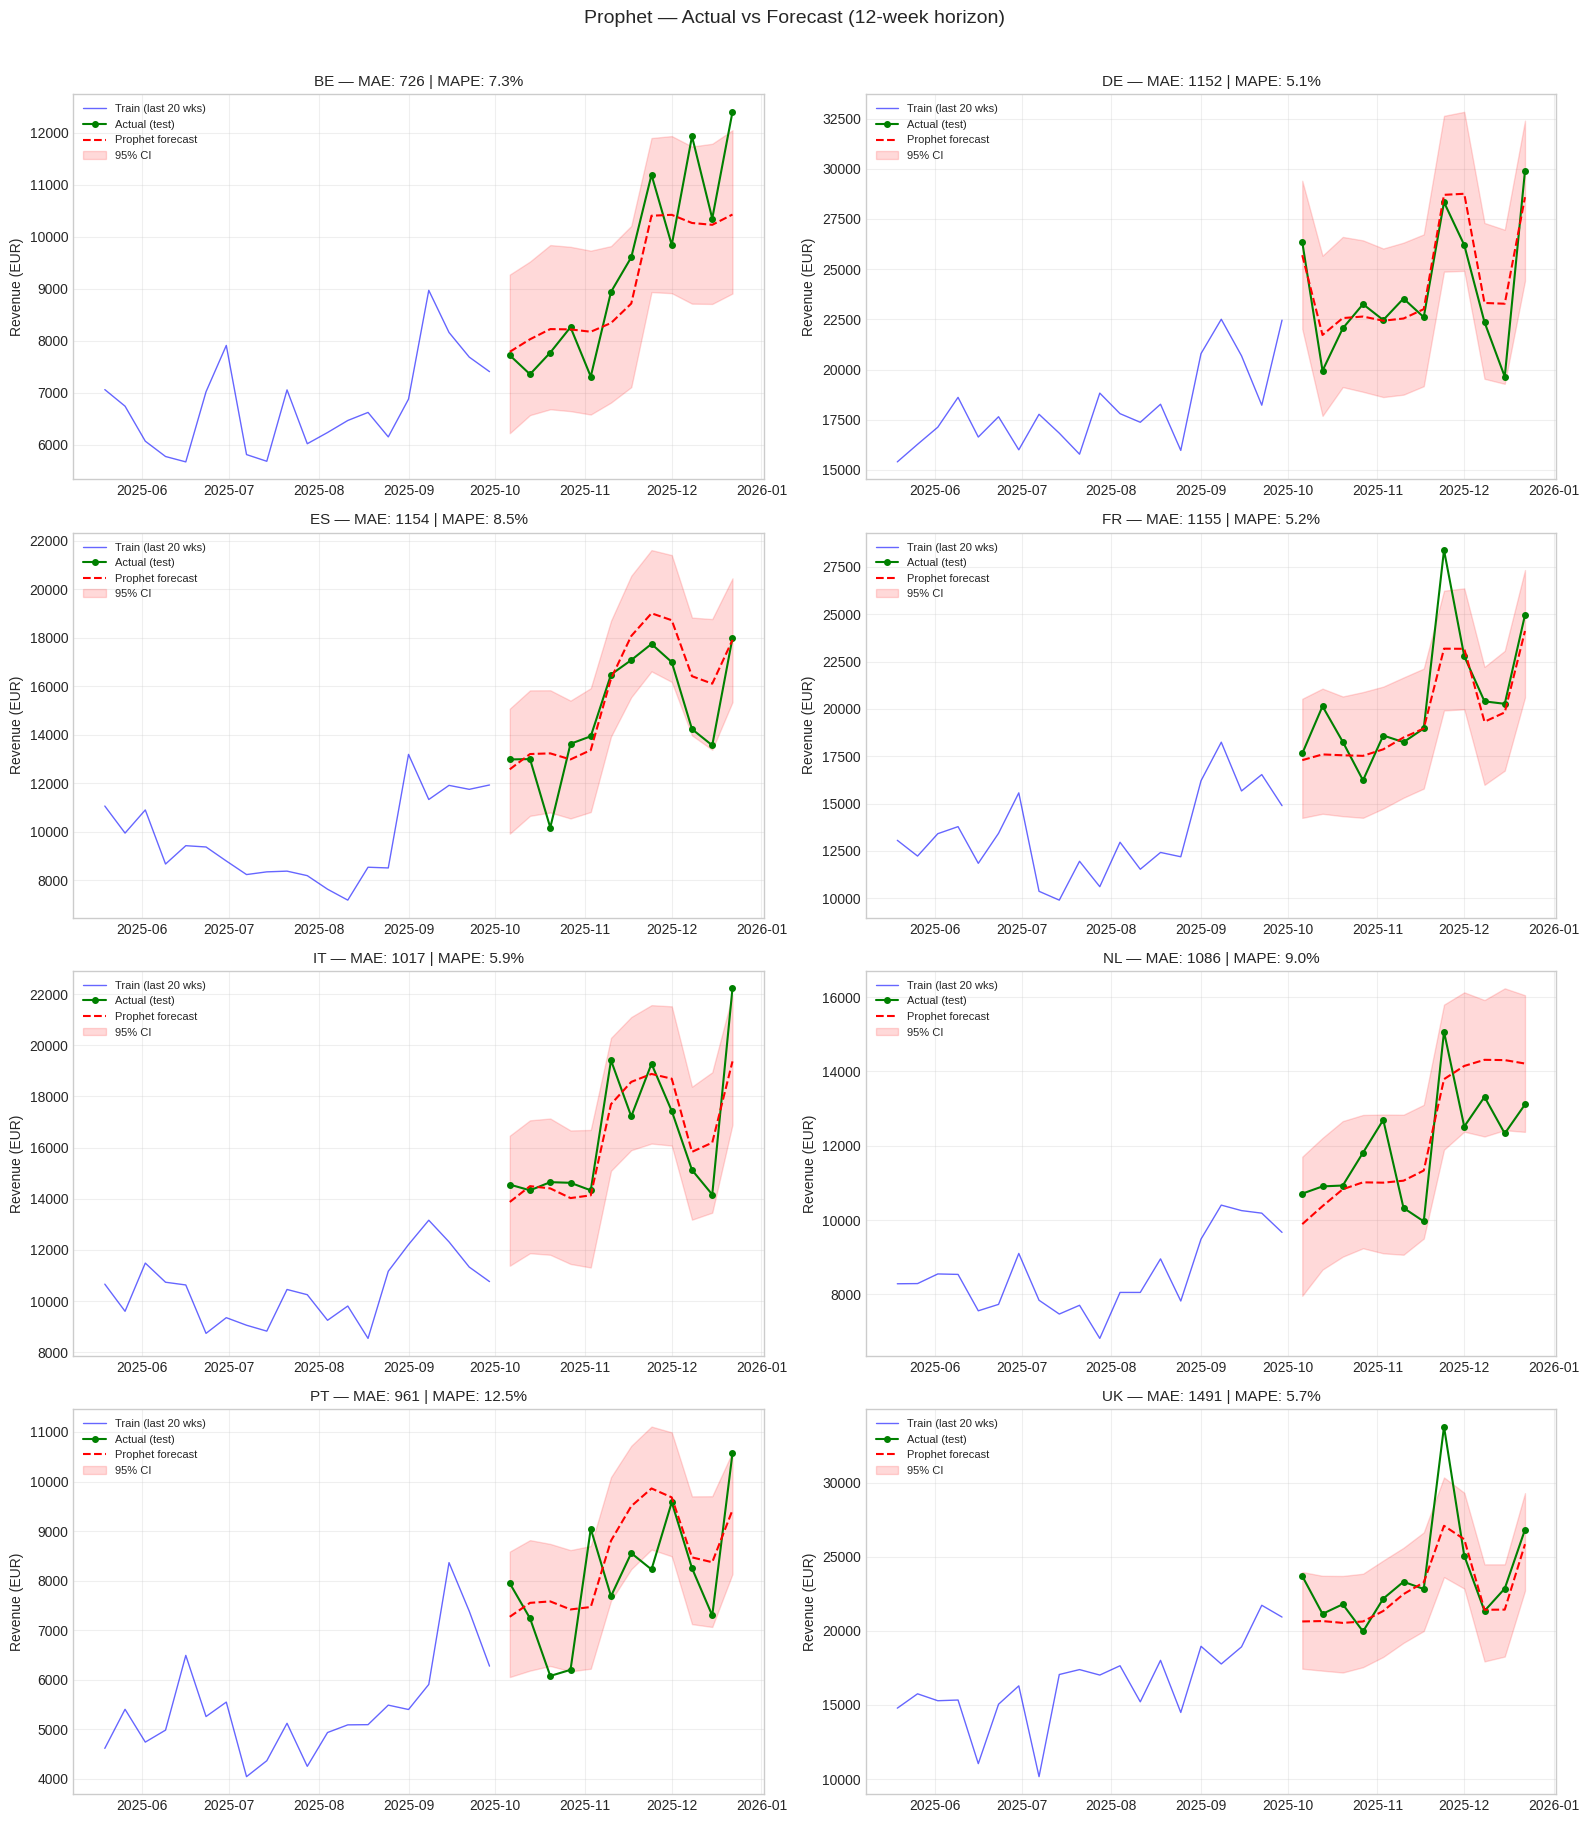

Forecast plot saved.


In [10]:
# Cell 9: Actual vs Predicted per country
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]
    test = prophet_test_data[country]
    forecast = prophet_forecasts[country]

    # Also show last 20 weeks of training for context
    train_tail = prophet_train_data[country].tail(20)

    ax.plot(train_tail['ds'], train_tail['y'],
            'b-', linewidth=1, alpha=0.6, label='Train (last 20 wks)')
    ax.plot(test['ds'], test['y'],
            'g-o', linewidth=1.5, markersize=4, label='Actual (test)')
    ax.plot(forecast['ds'], forecast['yhat'],
            'r--', linewidth=1.5, label='Prophet forecast')
    ax.fill_between(forecast['ds'], forecast['yhat_lower'], forecast['yhat_upper'],
                    alpha=0.15, color='red', label='95% CI')

    mae = country_metrics[country]['mae']
    mape = country_metrics[country]['mape']
    ax.set_title(f'{country} — MAE: {mae:.0f} | MAPE: {mape:.1f}%', fontsize=11)
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('Prophet — Actual vs Forecast (12-week horizon)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/prophet_forecast_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Forecast plot saved.')

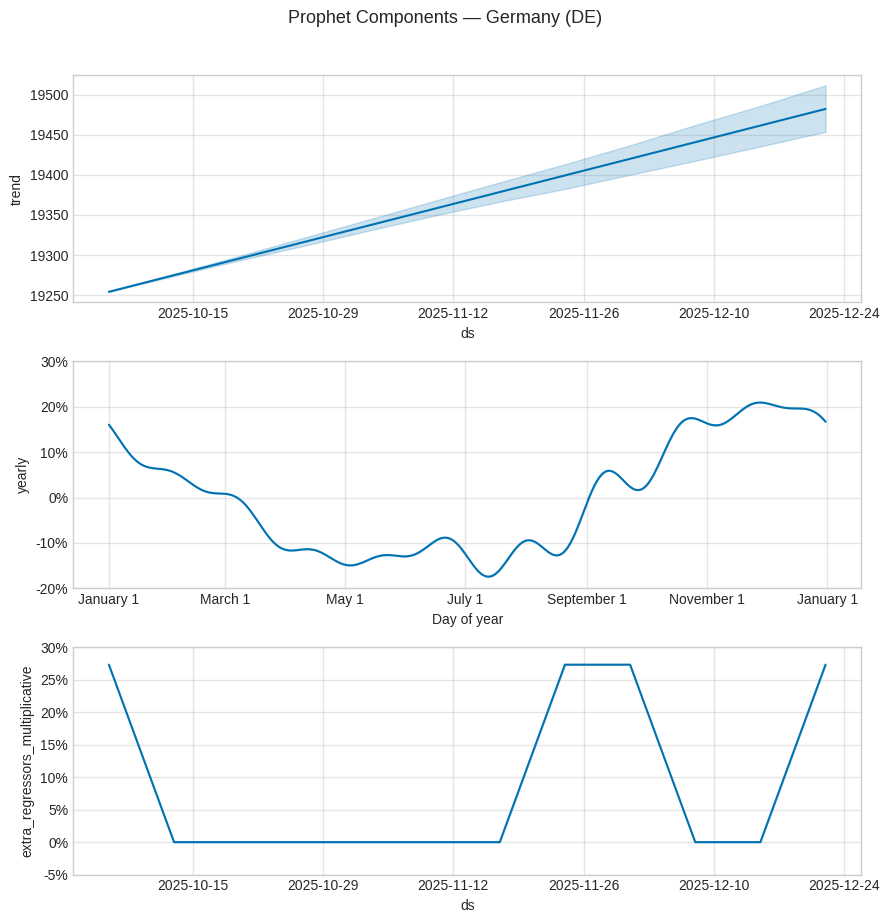

Component decomposition saved (DE example).


In [11]:
# Cell 10: Prophet component decomposition (example: Germany)
fig = prophet_models['DE'].plot_components(prophet_forecasts['DE'])
fig.suptitle('Prophet Components — Germany (DE)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/prophet_components_DE.png', dpi=150, bbox_inches='tight')
plt.show()
print('Component decomposition saved (DE example).')

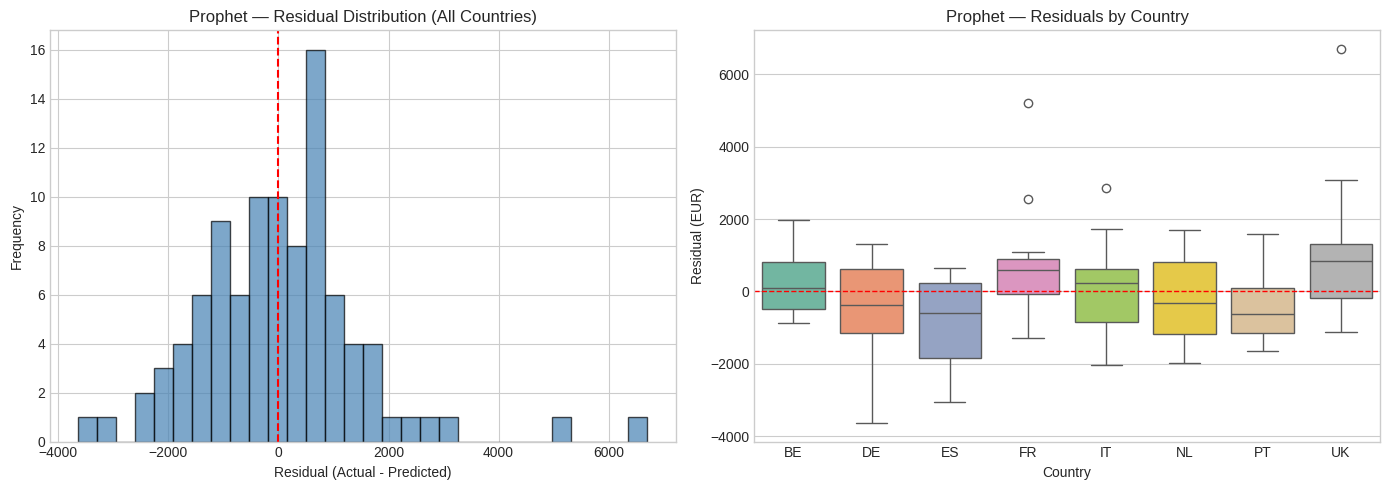

Residual analysis saved.


In [12]:
# Cell 11: Residual analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = np.array(all_actuals) - np.array(all_predictions)

# Histogram of residuals
axes[0].hist(residuals, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('Prophet — Residual Distribution (All Countries)')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].set_ylabel('Frequency')

# Residuals by country
residual_data = []
for country in countries:
    actual = prophet_test_data[country]['y'].values
    predicted = prophet_forecasts[country]['yhat'].values
    for r in (actual - predicted):
        residual_data.append({'country': country, 'residual': r})

res_df = pd.DataFrame(residual_data)
sns.boxplot(data=res_df, x='country', y='residual', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('Prophet — Residuals by Country')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Residual (EUR)')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/prophet_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Residual analysis saved.')

## Exporting results

Saving metrics and forecasts to JSON so I can line them up against TimesFM in Notebook 02.


In [13]:
# Cell 12: Save results to JSON
results = {
    'model_name': 'Prophet',
    'framework': 'Prophet (Meta)',
    'version': 'latest',
    'timestamp': datetime.now().isoformat(),
    'configuration': {
        'yearly_seasonality': True,
        'seasonality_mode': 'multiplicative',
        'changepoint_prior_scale': 0.05,
        'regressors': ['promotion_flag', 'covid_period_flag'],
        'forecast_horizon_weeks': FORECAST_HORIZON,
        'per_country_models': True,
    },
    'dataset': {
        'total_records': len(sales_df),
        'countries': countries,
        'date_range': f"{sales_df.week_start_date.min().date()} to {sales_df.week_start_date.max().date()}",
        'test_size_per_country': FORECAST_HORIZON,
    },
    'metrics': {
        'overall': {k: round(v, 4) for k, v in overall.items()},
        'per_country': {c: {k: round(v, 4) for k, v in m.items()}
                        for c, m in country_metrics.items()},
    },
    'training': {
        'total_time_seconds': round(total_training_time, 2),
        'per_country_seconds': {c: round(t, 2) for c, t in training_times.items()},
    },
    'forecasts': {
        country: {
            'dates': prophet_test_data[country]['ds'].dt.strftime('%Y-%m-%d').tolist(),
            'actual': prophet_test_data[country]['y'].tolist(),
            'predicted': prophet_forecasts[country]['yhat'].tolist(),
            'lower_bound': prophet_forecasts[country]['yhat_lower'].tolist(),
            'upper_bound': prophet_forecasts[country]['yhat_upper'].tolist(),
        }
        for country in countries
    },
}

# Save
results_path = f'{RESULTS_DIR}/prophet_results.json'
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f'Results saved to {results_path}')
print(f'\n=== PROPHET SUMMARY ===')
print(f'Overall MAE:   {overall["mae"]:.2f} EUR')
print(f'Overall RMSE:  {overall["rmse"]:.2f} EUR')
print(f'Overall MAPE:  {overall["mape"]:.2f}%')
print(f'Overall SMAPE: {overall["smape"]:.2f}%')
print(f'Training time: {total_training_time:.1f}s')

Results saved to /content/drive/MyDrive/ML_Prediction_Analysis/Prophet_Results/prophet_results.json

=== PROPHET SUMMARY ===
Overall MAE:   1092.77 EUR
Overall RMSE:  1507.09 EUR
Overall MAPE:  7.40%
Overall SMAPE: 7.30%
Training time: 2.1s


---

## Wrapping up

| Aspect | Detail |
|--------|--------|
| Model | Facebook Prophet |
| Approach | Per-country models (8 models) |
| Regressors | promotion_flag, covid_period_flag |
| Seasonality | Yearly (multiplicative) |
| Forecast horizon | 12 weeks |
| Hardware | CPU only |

What stood out:
1. Prophet's seasonality decomposition (trend + yearly + regressors) is genuinely useful for reading *why* a forecast looks the way it does, not just what it predicts.
2. The `promotion_flag` regressor earns its place — it visibly picks up the demand spikes around promotional events.
3. The COVID-period regressor helps absorb the 2020-2021 structural break instead of letting it distort the trend estimate.
4. Multiplicative seasonality fits better here than additive, given the markets are generally growing.

Next: TimesFM (Notebook 02), then the head-to-head comparison (Notebook 03).
